## Importing the dataset, removing the rows which miss and columns which are not needed ##

In [ ]:
import pandas as pd

df = pd.read_csv("datasets/ctdc_global_synthetic_data_v2026.csv") # import the dataset
df['isForcedLabour'] = df['isForcedLabour'].fillna(0).astype(int)


y = df["isForcedLabour"] # define the target variable

columns_to_drop = [ # define the columns to drop since they are not needed for the model training
    "isForcedLabour",
    "isSexualExploit",
    "isOtherExploit",
    "yearOfRegistration",
    "sectorOfSexPornography",
    "traffickMonths",
    'meansDebtBondageEarnings',
    'meansThreats',
    'meansAbusePsyPhySex',
    'meansFalsePromises',
    'meansDrugsAlcohol',
    'meansDenyBasicNeeds',
    'meansExcessiveWorkHours',
    'meansWithholdDocs'
]

X = df.drop(columns=columns_to_drop) # dropping the columns

print(X.shape[0], y.shape[0])

70205 70205


/tmp/ipykernel_50082/1112503863.py:3: DtypeWarning: Columns (1: gender, 2: ageBroad, 3: citizenship, 5: traffickMonths) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("datasets/ctdc_global_synthetic_data_v2026.csv") # import the dataset


## Importing the train_test_split method and splitting the data to two sets ##

In [ ]:
from sklearn.model_selection import train_test_split
"""
test_size=0.2 means 20% of the data will be used for testing and 80% for training
stratify=y keeps the same ratio of 0s and 1s in both sets
random_state=42 ensures reproducibility of the split
"""
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Training set shape:", X_train.shape[0], y_train.shape[0])
print("Testing set shape:", X_test.shape[0], y_test.shape[0])

Training set shape: 56164 56164
Testing set shape: 14041 14041


## Cleaning the data part 1 ##
**Setting up the translator**

In [3]:
"""
The translator works like a preprocessor for the model. It takes the raw input data and transforms it into a format that the model can understand.
"""

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Make two groups of columns: Numbers and words
categorical_columns = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
# print("categorical_columns :" , categorical_columns)
# print("numerical_columns :" , numerical_columns)

num_transformer = Pipeline(steps=[ # fill blanks with middle average, then balance number sizes
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[ # fill blanks with 'Unknown', then turn words into 1/0 checkboxes
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[ # Combine both sets of rules into one master preprocessor
    ('num', num_transformer, numerical_columns),
    ('cat', cat_transformer, categorical_columns)
])

print("Translator is ready")

Translator is ready


/tmp/ipykernel_50082/1029498494.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(include=['object', 'category']).columns.tolist()


## Cleaning the data part 2 ##

**Adding the lazy model**

In [ ]:
"""
The lazy model acts like a dumb model which we are going to use to compare our model with
"""

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

# 1. Connect our preprocessor to the lazy guesser
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

baseline_pipeline.fit(X_train, y_train) # Train the lazy guesser on our training data


baseline_scores = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='recall') # Test the lazy guesser 5 times on our training data to get its score

print("Baseline Mean Recall Score:",  baseline_scores.mean())

Baseline Mean Recall Score: 1.0


## Training using KNN ##
We are going to train the model using the "GridSearchCV" algorithm, this algorithm let us find the ideal __n_neigbors__ value without manually tinkering.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn = KNeighborsClassifier()

knn_pipeline = Pipeline(steps=[ # Connect our preprocessor to the KNN model
    ('preprocessor', preprocessor),
    ('classifier', knn)
])

param_grid = { # Define the hyperparameters to test
    'classifier__n_neighbors': [3, 5, 7, 9],
    'classifier__weights': ['uniform', 'distance'] # classifier__weights is a setting that tells the model how to weight the neighbors when making predictions. 'uniform' means all neighbors are weighted equally, while 'distance' means closer neighbors have more influence on the prediction.
}

knn_grid = GridSearchCV(
    knn_pipeline, # the model we want to test
    param_grid, # the hyperparameters we want to test
    cv=5, # number of folds for cross-validation
    scoring='recall', # the metric we want to optimize for
    n_jobs=-1 # use all available cores for parallel processing
)

print("Training KNN model in progress...")
knn_grid.fit(X_train, y_train) # Train the model on the training data

print("Best KNN parameters:", knn_grid.best_params_) # print the best hyperparameters found
print("Best KNN recall score:", knn_grid.best_score_) # print the best recall

Training KNN model in progress...
Best KNN parameters: {'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
Best KNN recall score: 0.49056349759801643


## Training using Logistic regression ##

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Force every fold to keep the exact same 0 and 1 ratio
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Create pipeline with preprocessor and Logistic Regression
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 3. Set parameter grid for C
logreg_param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0]
}

# 4. Set up GridSearchCV with StratifiedKFold
logreg_grid = GridSearchCV(
    logreg_pipeline, 
    logreg_param_grid, 
    cv=cv_stratified, 
    scoring='recall', 
    n_jobs=-1
)

# 5. Fit model
print("Training Logistic Regression model...")
logreg_grid.fit(X_train, y_train)

# 6. Print best parameters and recall
print(f"Best Logistic Regression parameters: {logreg_grid.best_params_}")
print(f"Best Logistic Regression recall score: {logreg_grid.best_score_:.4f}")

Training Logistic Regression model...
Best Logistic Regression parameters: {'classifier__C': 10.0}
Best Logistic Regression recall score: 0.3911


## Training using Random Forest ##

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(steps=[ # Connect our preprocessor to the Random Forest model
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

random_forest_param_grid = { # Define the hyperparameters to test
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 20, None]
}

random_forest_grid = GridSearchCV( # use grid search to find the best hyperparameters for the Random Forest model
    random_forest_pipeline, 
    random_forest_param_grid, 
    cv=cv_stratified, 
    scoring='recall', 
    n_jobs=-1
)

print("Training Random Forest model...")
random_forest_grid.fit(X_train, y_train)

print("Best Random Forest parameters" , random_forest_grid.best_params_)
print("Best Random Forest recall score: " , random_forest_grid.best_score_)

Training Random Forest model...
Best Random Forest parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 100}
Best Random Forest recall score: 0.5053


## Evaluating the models and diplaying the graphs ##

 FINAL TEST RESULTS: BASELINE (DUMMY) 
              precision    recall  f1-score   support

           0     0.7385    1.0000    0.8496     39662
           1     0.0000    0.0000    0.0000     14041

    accuracy                         0.7385     53703
   macro avg     0.3693    0.5000    0.4248     53703
weighted avg     0.5454    0.7385    0.6275     53703



/home/user/Desktop/hackathon-week5-classifiers/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/user/Desktop/hackathon-week5-classifiers/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/user/Desktop/hackathon-week5-classifiers/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this b

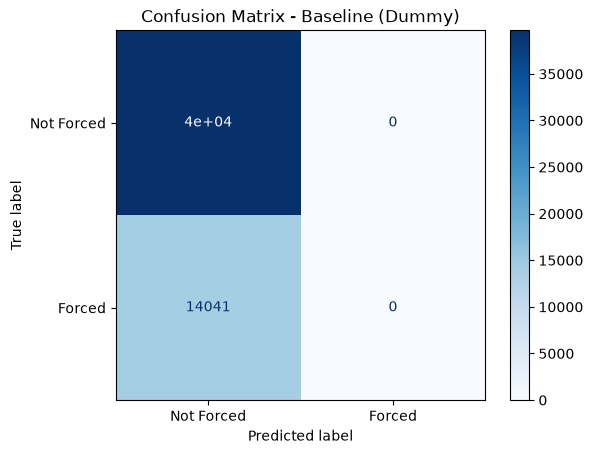

 FINAL TEST RESULTS: LOGISTIC REGRESSION 
              precision    recall  f1-score   support

           0     0.8146    0.9340    0.8703     39662
           1     0.6820    0.3997    0.5040     14041

    accuracy                         0.7943     53703
   macro avg     0.7483    0.6669    0.6871     53703
weighted avg     0.7800    0.7943    0.7745     53703



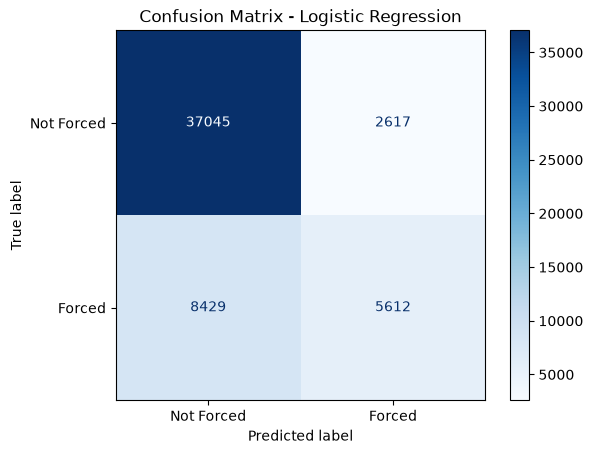

 FINAL TEST RESULTS: KNN 
              precision    recall  f1-score   support

           0     0.8337    0.8791    0.8558     39662
           1     0.5965    0.5047    0.5467     14041

    accuracy                         0.7812     53703
   macro avg     0.7151    0.6919    0.7013     53703
weighted avg     0.7717    0.7812    0.7750     53703



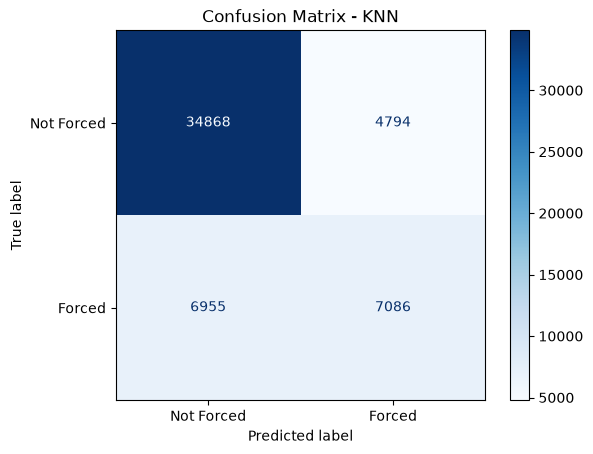

 FINAL TEST RESULTS: RANDOM FOREST 
              precision    recall  f1-score   support

           0     0.8406    0.9252    0.8809     39662
           1     0.7047    0.5044    0.5880     14041

    accuracy                         0.8152     53703
   macro avg     0.7727    0.7148    0.7344     53703
weighted avg     0.8051    0.8152    0.8043     53703



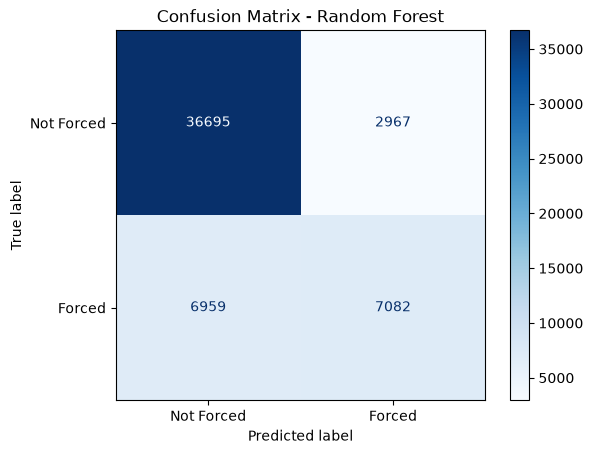

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

# 1. Fit baseline model
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])
baseline_pipeline.fit(X_train, y_train)

# 2. Store all trained models
models = {
    'Baseline (Dummy)': baseline_pipeline,
    'Logistic Regression': logreg_grid.best_estimator_,
    'KNN': knn_grid.best_estimator_,
    'Random Forest': random_forest_grid.best_estimator_
}

# 3. Evaluate each model and plot confusion matrices
for name, model in models.items():
    y_pred = model.predict(X_test)
    
    print("=" * 60) # this line prints a separator for better readability
    print(f" FINAL TEST RESULTS: {name.upper()} ") # this line prints the name of the model being evaluated
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=4, zero_division=0)) # this line prints the following metrics: precision, recall, f1-score, and support for each class (0 and 1) as well as the overall accuracy, macro average, and weighted average. 0 means Not Forced, 1 means Forced. The digits=4 argument specifies that the metrics should be displayed with 4 decimal places.
    
    # Generate and plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Forced', 'Forced'])
    
    display.plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()